# 02 – ColoredMNIST: Deep Feature Reweighting (DFR)

This notebook loads the ERM-trained backbone from notebook 01, extracts frozen features, and retrains the last linear layer with L2-regularized logistic regression on the group-balanced validation set. This is the DFR procedure from Kirichenko et al. (ICLR 2023).


In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


In [3]:
## 1) Model Architecture: (same SmallCNN as notebook 01 to be able to load weights

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(64 * 7 * 7, 128)  # produces 128-dim feature embedding
        self.fc2 = nn.Linear(128, 2)            # original ERM classification head

    def forward(self, x, return_feat=False):
        h = self.conv(x)
        h = h.view(h.size(0), -1)
        feat = F.relu(self.fc1(h))  # 128-dim embedding
        out = self.fc2(feat)
        if return_feat:
            return out, feat
        return out


In [4]:
## 2) Load Pretrained ERM Backbone
# Load the weights saved at the end of notebook 01. The backbone is kept frozen
# Only the last layer will be replaced by DFR.
model = SmallCNN().to(device)
model.load_state_dict(torch.load("mnist_erm_cnn.pth", map_location=device, weights_only=True))
model.eval()
print("ERM backbone loaded successfully.")


SmallCNN(
  (conv): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)

In [5]:
## 3) ColoredMNIST Dataset (validation + test splits)
from torchvision.datasets import MNIST

class ColoredMNIST(torch.utils.data.Dataset):
    def __init__(self, root="./data", split="train", rho=0.95, download=False):
        assert split in ["train", "val_clean", "test_spurious", "test_clean"]
        self.base = MNIST(root=root, train=(split in ["train", "val_clean"]), download=download)
        self.X = self.base.data.float() / 255.0
        self.y_digit = self.base.targets.long()
        self.y = (self.y_digit < 5).long()  # binary label: digits 0-4 → 1, digits 5-9 → 0

        rng = np.random.RandomState(42 if "test" in split else 0)
        y_np = self.y.numpy()

        if split == "test_clean":
            z = rng.randint(0, 2, len(y_np))  # random color — spurious cue disabled
        else:
            # Assign color to match label with probability rho
            match = rng.rand(len(y_np)) < rho
            z = np.where(match, y_np, 1 - y_np)

        self.z = torch.tensor(z).long()
        self.groups = self.y * 2 + self.z  # group index g = y*2 + z ∈ {0,1,2,3}

        if split == "val_clean":
            # Build group-balanced subset: at most 200 samples per group
            ids_per_group = [torch.where(self.groups == g)[0].tolist() for g in range(4)]
            min_n = min(len(ids) for ids in ids_per_group)
            min_n = min(min_n, 200)
            balanced_ids = []
            for ids in ids_per_group:
                rng.shuffle(ids)
                balanced_ids.extend(ids[:min_n])
            balanced_ids = sorted(balanced_ids)
            self.X = self.X[balanced_ids]
            self.y = self.y[balanced_ids]
            self.z = self.z[balanced_ids]
            self.groups = self.groups[balanced_ids]

    def __len__(self): return len(self.y)

    def colorize(self, img, z):
        # Apply color tint: z=0 → red, z=1 → green (channel scaling on grayscale image)
        img3 = torch.stack([img, img, img], dim=0)
        if z == 0: scale = torch.tensor([1.0, 0.5, 0.5]).view(3, 1, 1)
        else:      scale = torch.tensor([0.5, 1.0, 0.5]).view(3, 1, 1)
        return (img3 * scale).clamp(0, 1)

    def __getitem__(self, idx):
        img, y, z, g = self.X[idx], int(self.y[idx]), int(self.z[idx]), int(self.groups[idx])
        img = self.colorize(img, z)
        return img, y, z, g


In [6]:
## 4) Build DataLoaders
val_clean     = ColoredMNIST(split="val_clean",     rho=0.95, download=False)
test_spurious = ColoredMNIST(split="test_spurious", rho=0.95, download=False)
test_clean    = ColoredMNIST(split="test_clean",    rho=0.95, download=False)

val_loader     = DataLoader(val_clean,     batch_size=256, shuffle=False)
test_sp_loader = DataLoader(test_spurious, batch_size=256, shuffle=False)
test_cl_loader = DataLoader(test_clean,    batch_size=256, shuffle=False)

print("val_clean size:",     len(val_clean))
print("test_spurious size:", len(test_spurious))
print("test_clean size:",    len(test_clean))


val_clean boyutu: 800
test_spurious boyutu: 10000
test_clean boyutu: 10000


In [7]:
## 5) Feature Extraction (frozen backbone)
# Pass all samples through the frozen ERM backbone to obtain 128-dim embeddings.
@torch.no_grad()
def extract_features(model, loader):
    model.eval()
    Xs, ys, gs = [], [], []
    for x, y, _, g in loader:
        x = x.to(device)
        logits, feat = model(x, return_feat=True)  # feat: 128-dim embedding
        Xs.append(feat.cpu().numpy())
        ys.append(y.numpy())
        gs.append(g.numpy())
    return np.concatenate(Xs), np.concatenate(ys), np.concatenate(gs)

X_val, y_val, g_val = extract_features(model, val_loader)
X_sp,  y_sp,  g_sp  = extract_features(model, test_sp_loader)
X_cl,  y_cl,  g_cl  = extract_features(model, test_cl_loader)

print("Feature shapes -> val:", X_val.shape, "| test_spurious:", X_sp.shape, "| test_clean:", X_cl.shape)


Özellik boyutları -> (800, 128) (10000, 128) (10000, 128)


In [8]:
## 6) DFR: Train Logistic Regression on Balanced Validation Features
# The val_clean set is already group-balanced (built in the Dataset class).
# We fit a logistic regression on the frozen features, this is the DFR last-layer retraining part.
clf = LogisticRegression(penalty="l2", solver="saga", max_iter=1000)
clf.fit(X_val, y_val)
print("DFR head trained on val_clean features.")


LogisticRegression(max_iter=1000, solver='saga')

In [9]:
## 7) Evaluate on Test Sets
def eval_lr(clf, X, y, g, tag="set"):
    preds = clf.predict(X)
    acc = accuracy_score(y, preds)
    # Per-group accuracy to compute worst-group metric
    accs = {}
    for gi in np.unique(g):
        mask = g == gi
        accs[gi] = accuracy_score(y[mask], preds[mask])
    worst = min(accs.values())
    print(f"[{tag}] mean={acc:.3f}, worst={worst:.3f}, groups={accs}")

eval_lr(clf, X_sp, y_sp, g_sp, tag="Test Spurious (DFR)")
eval_lr(clf, X_cl, y_cl, g_cl, tag="Test Clean    (DFR)")


[Test Spurious] mean=0.992, worst=0.915, groups={0: 0.9932972972972973, 1: 0.9152542372881356, 2: 0.9453781512605042, 3: 0.9971434401142624}
[Test Clean] mean=0.977, worst=0.949, groups={0: 0.9930838079739626, 1: 0.9488139825218477, 2: 0.9667318982387475, 3: 0.9976780185758514}


In [10]:
## 8) Compare: ERM Head vs DFR Head

@torch.no_grad()
def eval_erm_head(model, loader, tag="ERM"):
    # Evaluate the original ERM classification head (fc2) on a given loader.
    model.eval()
    y_all, g_all, p_all = [], [], []
    for x, y, _, g in loader:  # loader yields (img, y, z, g)
        x = x.to(device)
        logits = model(x)  # use the original fc2 head
        p = logits.argmax(1).cpu().numpy()
        y_all.append(y.numpy())
        g_all.append(g.numpy())
        p_all.append(p)
    y = np.concatenate(y_all)
    g = np.concatenate(g_all)
    p = np.concatenate(p_all)
    mean = (p == y).mean()
    accs = {gi: (p[g == gi] == y[g == gi]).mean() for gi in np.unique(g)}
    worst = min(accs.values())
    print(f"[{tag}] mean={mean:.3f}, worst={worst:.3f}, groups={accs}")

print("=== ERM (original classification head) ===")
eval_erm_head(model, test_sp_loader, tag="Test Spurious (ERM)")
eval_erm_head(model, test_cl_loader, tag="Test Clean    (ERM)")

print("\n=== DFR (logistic regression head) ===")
eval_lr(clf, X_sp, y_sp, g_sp, tag="Test Spurious (DFR)")
eval_lr(clf, X_cl, y_cl, g_cl, tag="Test Clean    (DFR)")


=== ERM (orijinal kafa) ===
[Test Spurious (ERM)] mean=0.989, worst=0.809, groups={0: 0.9872432432432432, 1: 0.809322033898305, 2: 0.9705882352941176, 3: 1.0}
[Test Clean (ERM)] mean=0.952, worst=0.836, groups={0: 0.9869812855980472, 1: 0.8360382854764877, 2: 0.9772994129158513, 3: 1.0}

=== DFR (lojistik regresyon) — referans ===
[Test Spurious (DFR)] mean=0.992, worst=0.915, groups={0: 0.9932972972972973, 1: 0.9152542372881356, 2: 0.9453781512605042, 3: 0.9971434401142624}
[Test Clean (DFR)] mean=0.977, worst=0.949, groups={0: 0.9930838079739626, 1: 0.9488139825218477, 2: 0.9667318982387475, 3: 0.9976780185758514}


In [11]:
## 9) Sensitivity to Spurious Correlation Strength (ρ = 0.99)
# Re-evaluate with a stronger spurious correlation to test DFR robustness.
test_spurious_99  = ColoredMNIST(split="test_spurious", rho=0.99, download=False)
test_sp99_loader  = DataLoader(test_spurious_99, batch_size=256, shuffle=False)

print("test_spurious (ρ=0.95):", len(test_spurious))
print("test_spurious (ρ=0.99):", len(test_spurious_99))

# Extract features using the same frozen backbone
X_sp99, y_sp99, g_sp99 = extract_features(model, test_sp99_loader)

print("\n=== ERM (ρ=0.99, Spurious Test) ===")
eval_erm_head(model, test_sp99_loader, tag="Test Spurious ρ=0.99 (ERM)")

print("\n=== DFR (ρ=0.99, Spurious Test) ===")
eval_lr(clf, X_sp99, y_sp99, g_sp99, tag="Test Spurious ρ=0.99 (DFR)")


test_spurious_95: 10000
test_spurious_99: 10000

=== ERM (ρ=0.99, Spurious Test) ===
[Test Spurious ρ=0.99 (ERM)] mean=0.993, worst=0.860, groups={0: 0.9865089248650892, 1: 0.8604651162790697, 2: 1.0, 3: 1.0}

=== DFR (ρ=0.99, Spurious Test) ===
[Test Spurious ρ=0.99 (DFR)] mean=0.995, worst=0.907, groups={0: 0.9931506849315068, 1: 0.9069767441860465, 2: 0.9534883720930233, 3: 0.9970565149136578}


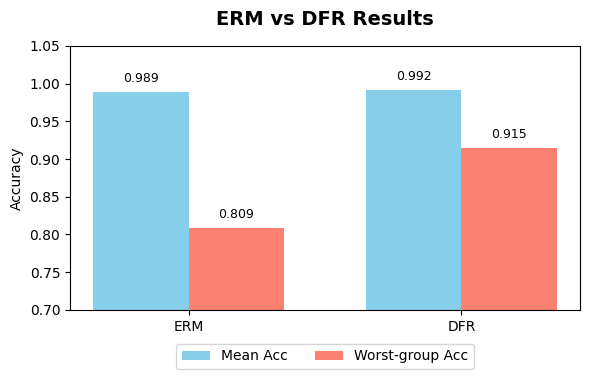

In [33]:
## 10) Visualization: ERM vs DFR Results (Bar Chart)
import matplotlib.pyplot as plt
import numpy as np

# Results from this experiment (spurious test set, ρ=0.95)
methods  = ["ERM", "DFR"]
mean_acc  = [0.989, 0.992]
worst_acc = [0.809, 0.915]

x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(6, 4))

bars1 = ax.bar(x - width / 2, mean_acc,  width, label="Mean Acc",         color="skyblue")
bars2 = ax.bar(x + width / 2, worst_acc, width, label="Worst-Group Acc",  color="salmon")

# Annotate bar values
for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f"{height:.3f}",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)

ax.set_title("ERM vs DFR — ColoredMNIST (Spurious Test)", pad=12, fontsize=13, fontweight="bold")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.25), ncol=2)
ax.set_ylim(0.7, 1.05)
ax.set_ylabel("Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(methods)

plt.tight_layout()
plt.show()


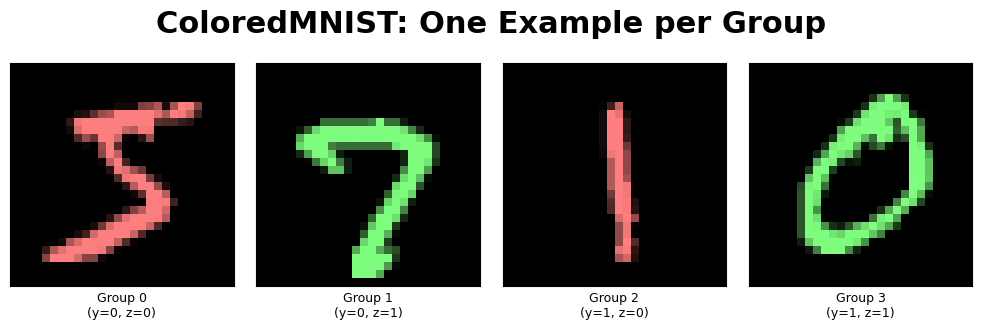

In [31]:
## 11) Visualization: One Example per Group
import matplotlib.pyplot as plt

# Build the training split to show examples
train_ds = ColoredMNIST(split="train", rho=0.95, download=False)

# Find one sample index per group
examples = []
for g in range(4):
    idx = (train_ds.groups == g).nonzero(as_tuple=True)[0][0].item()
    examples.append(idx)

# Plot one image per group
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i, idx in enumerate(examples):
    img, y, z, g = train_ds[idx]
    axes[i].imshow(img.permute(1, 2, 0))
    axes[i].set_xlabel(f"Group {g}\n(y={y}, z={z})", fontsize=9)
    axes[i].set_xticks([])
    axes[i].set_yticks([])

plt.suptitle("ColoredMNIST: One Example per Group", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
